# Machine Learning Classification Project: Heart Disease Prediction

## Problem Statement
Predict the presence or absence of heart disease based on various clinical and demographic features. This exercise will cover the complete machine learning pipeline from data preprocessing to model evaluation.

## Dataset
The dataset contains 918 instances with 11 clinical features and 1 target variable:

**Features:**
1. Age: Age of the patient (years)
2. Sex: Gender of the patient (M: Male, F: Female)
3. ChestPainType: Type of chest pain (TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic)
4. RestingBP: Resting blood pressure (mm Hg)
5. Cholesterol: Serum cholesterol (mg/dl)
6. FastingBS: Fasting blood sugar (1: if FastingBS > 120 mg/dl, 0: otherwise)
7. RestingECG: Resting electrocardiogram results (Normal, ST, LVH)
8. MaxHR: Maximum heart rate achieved
9. ExerciseAngina: Exercise-induced angina (Y: Yes, N: No)
10. Oldpeak: Oldpeak = ST depression induced by exercise relative to rest
11. ST_Slope: Slope of the peak exercise ST segment (Up, Flat, Down)

**Target:**
12. HeartDisease: Presence of heart disease (1: yes, 0: no)

## Task 1: Data Loading and Initial Exploration
- Load the dataset
- Display basic information (shape, data types, null values)
- Generate descriptive statistics
- Check for class distribution (target variable)

Shape (rows, columns): (1025, 14)

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Null values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak  

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2



Class distribution (0 = no disease, 1 = disease):
target
1    526
0    499
Name: count, dtype: int64
target
1    0.513
0    0.487
Name: proportion, dtype: float64


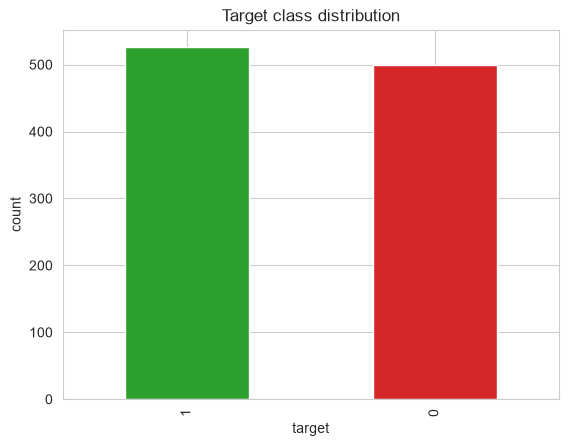

In [1]:
# Task 1: Load the data and explore it
import warnings
import pickle, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, learning_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

df = pd.read_csv("heart.csv")

print("Shape (rows, columns):", df.shape)
print("\nData types and non-null counts:")
df.info()
print("\nNull values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
display(df.head())
display(df.describe().T)

# Class distribution of the target
print("\nClass distribution (0 = no disease, 1 = disease):")
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True).round(3))
df["target"].value_counts().plot(kind="bar", color=["tab:green", "tab:red"], title="Target class distribution")
plt.xlabel("target"); plt.ylabel("count"); plt.show()

## Task 2: Data Preprocessing
- Handle missing values (if any)
- Encode categorical variables (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope)
- Scale/normalize numerical features
- Check for class imbalance
- Split data into features (X) and target (y)

In [2]:
# Task 2: Preprocessing

# 1) Missing values: there are none, but this line would fill any numeric gaps with the median
df = df.fillna(df.median(numeric_only=True))

# The file has many exact duplicate rows (same patient copied). If we keep them, the same row
# can land in both train and test sets, which makes scores look unrealistically high. So we remove them.
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

# 2) Split into features (X) and target (y)
X = df.drop("target", axis=1)
y = df["target"]

# 3) Encode categorical variables.
# In this dataset categories are already stored as numbers (codes), but cp, restecg, slope and thal
# are NOT ordered (3 is not "more" than 1), so we one-hot encode them.
# sex, fbs and exang are already 0/1, so they stay as they are.
categorical_cols = ["cp", "restecg", "slope", "thal"]
binary_cols = ["sex", "fbs", "exang"]
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

# 4) Scale numeric features (StandardScaler: mean 0, std 1)
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols),
], remainder="passthrough")   # binary columns pass through unchanged

# Quick look at what the preprocessor produces (inside the models it is fitted on training data only,
# so no information from the test set leaks into training)
X_demo = preprocessor.fit_transform(X)
print("Features before encoding:", X.shape[1], "-> after encoding + scaling:", X_demo.shape[1])

# 5) Check class imbalance
print("\nClass balance:")
print(y.value_counts(normalize=True).round(3))
print("The classes are roughly balanced, so no resampling (like SMOTE) is needed.")

Shape after removing duplicates: (302, 14)
Features before encoding: 13 -> after encoding + scaling: 23

Class balance:
target
1    0.543
0    0.457
Name: proportion, dtype: float64
The classes are roughly balanced, so no resampling (like SMOTE) is needed.


## Task 3: Exploratory Data Analysis (EDA)
- Plot correlation matrix heatmap
- Create distribution plots for numerical features
- Visualize relationships between features and target
- Create pairplots for selected features

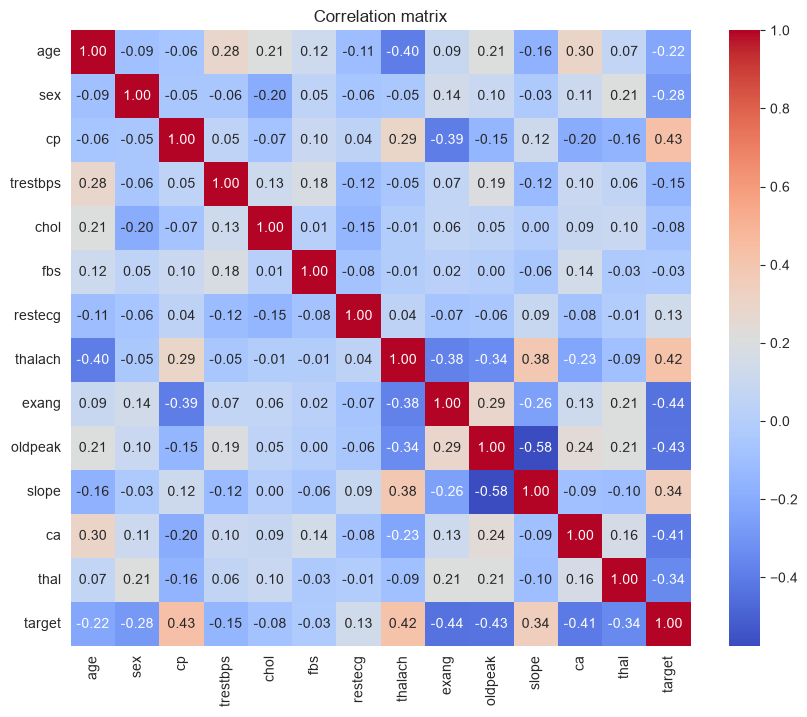

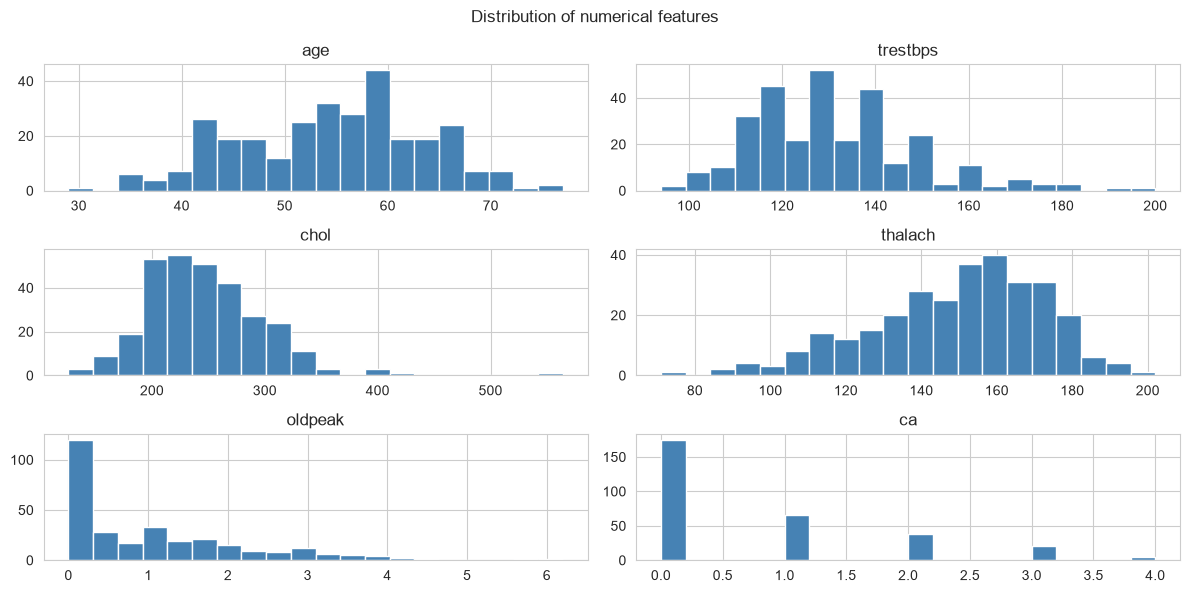

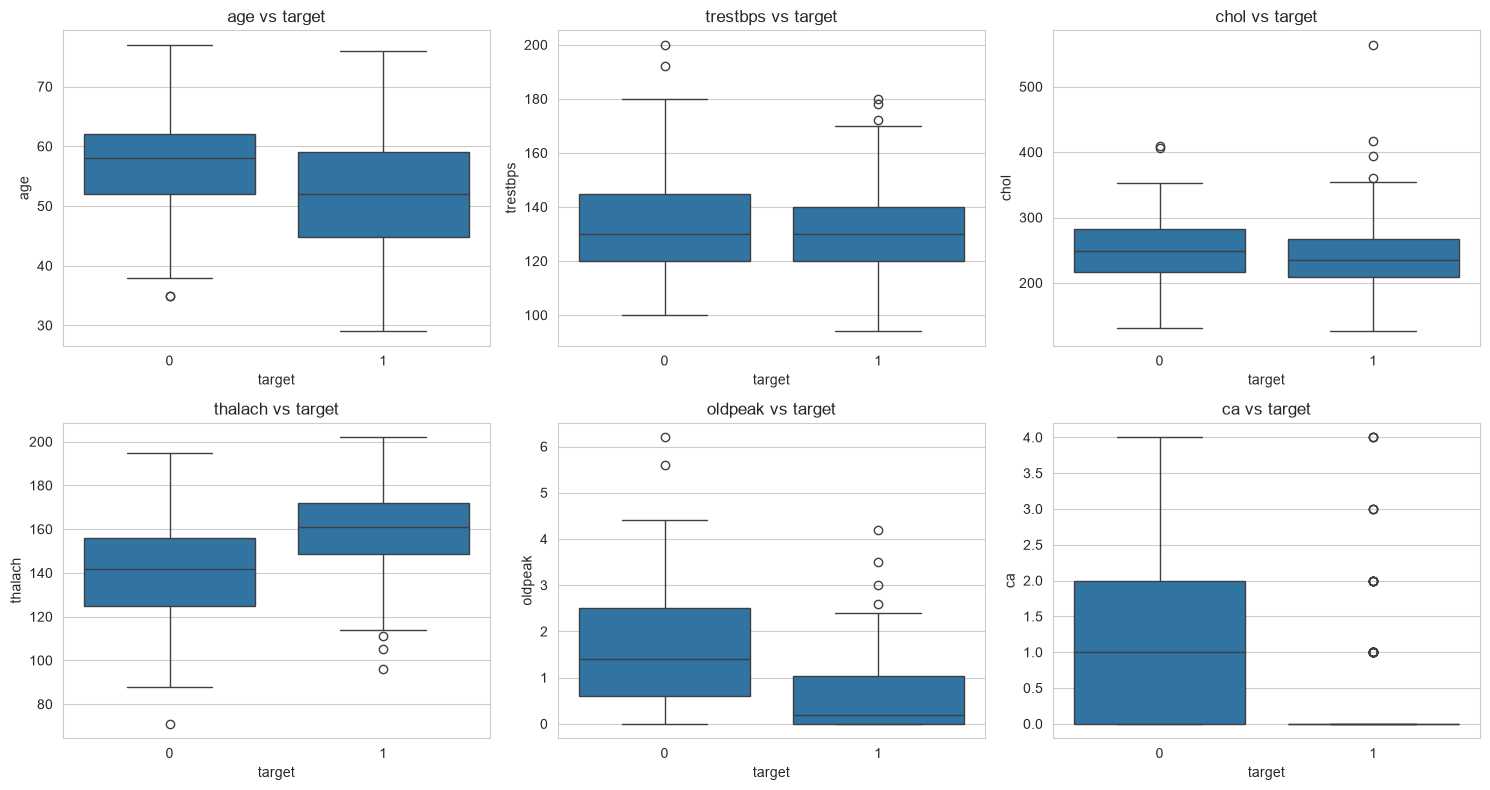

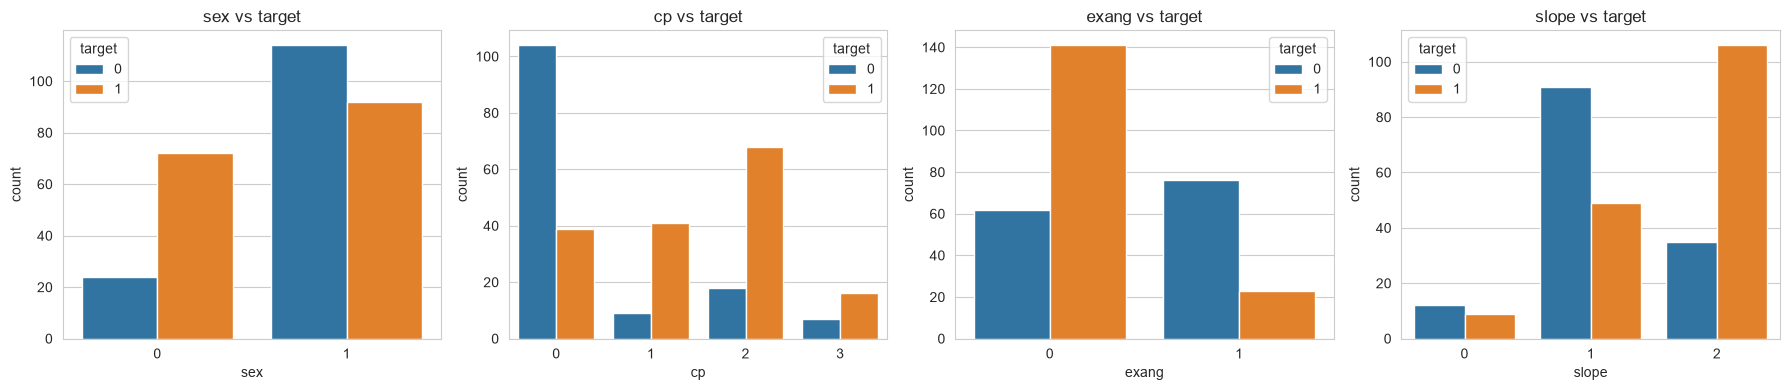

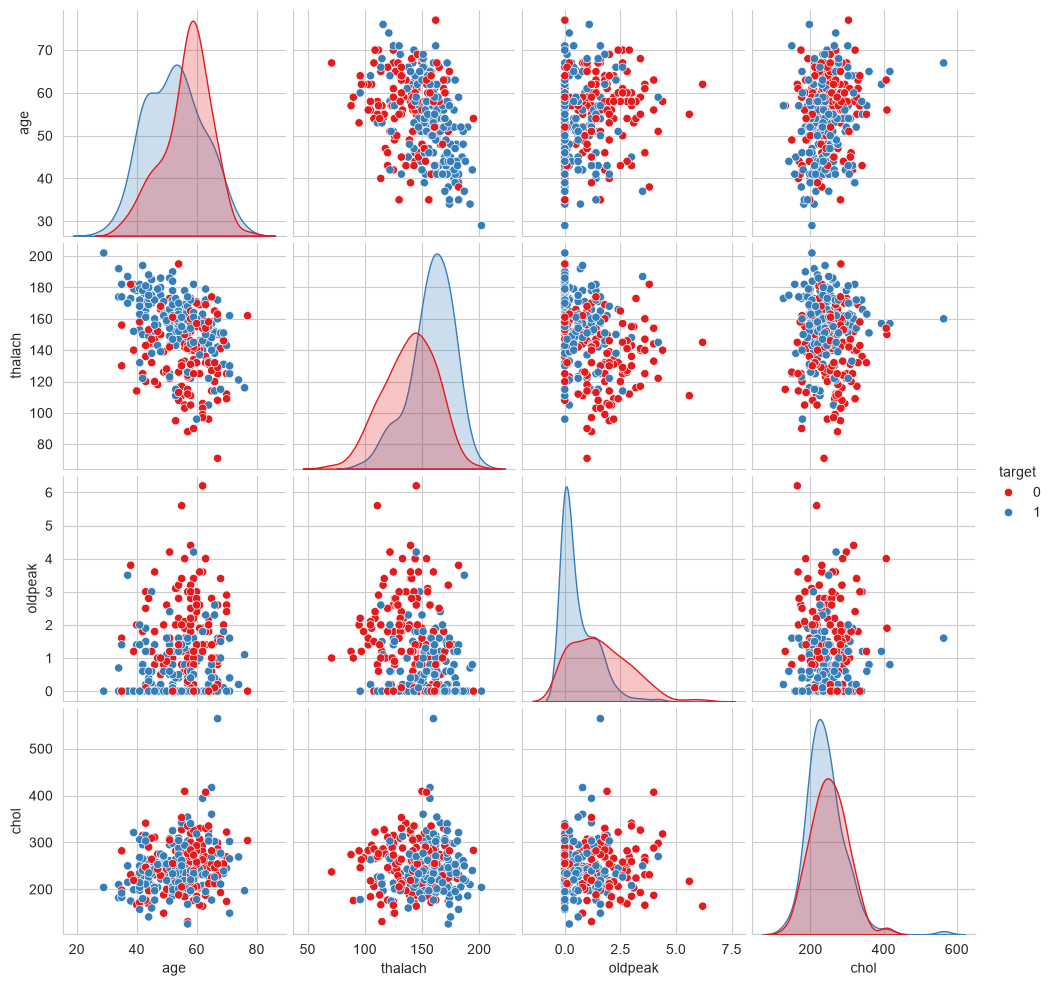

In [3]:
# Task 3: Exploratory Data Analysis

# 1) Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

# 2) Distribution of numerical features
df[numeric_cols].hist(bins=20, figsize=(12, 6), color="steelblue")
plt.suptitle("Distribution of numerical features"); plt.tight_layout(); plt.show()

# 3) Relationship between features and target
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
    ax.set_title(f"{col} vs target")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["sex", "cp", "exang", "slope"]):
    sns.countplot(data=df, x=col, hue="target", ax=ax)
    ax.set_title(f"{col} vs target")
plt.tight_layout(); plt.show()

# 4) Pairplot of selected features
sns.pairplot(df[["age", "thalach", "oldpeak", "chol", "target"]], hue="target", palette="Set1")
plt.show()

## Task 4: Data Splitting and Cross-Validation Setup
- Split data into training (80%) and testing (20%) sets
- Implement K-Fold cross-validation (k=5 or k=10)
- Explain the purpose of cross-validation in reducing overfitting

In [4]:
# Task 4: Train/test split (80/20) and K-Fold cross-validation setup
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify keeps the same class ratio in both parts
print("Train:", X_train.shape, " Test:", X_test.shape)

# 5-fold stratified cross-validation (used for every model below)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Quick demo of cross-validation with a simple Logistic Regression
demo = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])
scores = cross_val_score(demo, X_train, y_train, cv=cv, scoring="accuracy")
print("Accuracy in each fold:", scores.round(3))
print(f"Mean accuracy: {scores.mean():.3f}  (+/- {scores.std():.3f})")

Train: (241, 13)  Test: (61, 13)
Accuracy in each fold: [0.878 0.792 0.854 0.958 0.708]
Mean accuracy: 0.838  (+/- 0.084)


**Why cross-validation?** If we train and test on the same split only once, the score depends on luck: the split may be easy or hard. In K-Fold CV the training data is cut into K parts (here 5). The model is trained on 4 parts and validated on the 5th, and this is repeated so every part is used for validation once. The average score is a more reliable estimate of how the model behaves on unseen data. It reduces overfitting because (1) we can spot a model that only memorises the training data (good on train, bad on validation folds) and (2) hyperparameters are chosen by their average validation score, not by one lucky split. The test set is kept untouched until the final evaluation.

## Task 5: Model Implementation and Training
Implement and compare the following algorithms:
1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree Classifier
4. Random Forest Classifier
5. Support Vector Machine (SVM)

For each algorithm:
- Initialize the model with appropriate parameters
- Train using cross-validation
- Perform hyperparameter tuning

### 5.1 K-Nearest Neighbors (KNN)

In [6]:
best_models = {}   # tuned models are stored here
cv_scores = {}     # their cross-validated F1 scores
# KNN: pipeline = preprocessing + model, tuned with GridSearchCV (5-fold CV on training data)
pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier())])
param_grid = {"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
best_models["KNN"] = grid.best_estimator_
cv_scores["KNN"] = grid.best_score_
print("Best parameters:", grid.best_params_)
print("Best cross-validated F1:", round(grid.best_score_, 3))

Best parameters: {'model__n_neighbors': 15, 'model__weights': 'uniform'}
Best cross-validated F1: 0.853


### 5.2 Logistic Regression

In [6]:
# Logistic Regression: pipeline = preprocessing + model, tuned with GridSearchCV (5-fold CV on training data)
pipe = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])
param_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
best_models["Logistic Regression"] = grid.best_estimator_
cv_scores["Logistic Regression"] = grid.best_score_
print("Best parameters:", grid.best_params_)
print("Best cross-validated F1:", round(grid.best_score_, 3))

Best parameters: {'model__C': 0.1}
Best cross-validated F1: 0.874


### 5.3 Decision Tree Classifier

In [7]:
# Decision Tree: pipeline = preprocessing + model, tuned with GridSearchCV (5-fold CV on training data)
pipe = Pipeline([("prep", preprocessor), ("model", DecisionTreeClassifier(random_state=42))])
param_grid = {"model__max_depth": [2, 3, 4, 5, 7, None], "model__min_samples_leaf": [1, 5, 10]}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
best_models["Decision Tree"] = grid.best_estimator_
cv_scores["Decision Tree"] = grid.best_score_
print("Best parameters:", grid.best_params_)
print("Best cross-validated F1:", round(grid.best_score_, 3))

Best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 5}
Best cross-validated F1: 0.825


### 5.4 Random Forest Classifier

In [8]:
# Random Forest: pipeline = preprocessing + model, tuned with GridSearchCV (5-fold CV on training data)
pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(random_state=42))])
param_grid = {"model__n_estimators": [100, 200], "model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5]}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
best_models["Random Forest"] = grid.best_estimator_
cv_scores["Random Forest"] = grid.best_score_
print("Best parameters:", grid.best_params_)
print("Best cross-validated F1:", round(grid.best_score_, 3))

Best parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}
Best cross-validated F1: 0.878


### 5.5 Support Vector Machine (SVM)

In [9]:
# SVM: pipeline = preprocessing + model, tuned with GridSearchCV (5-fold CV on training data)
pipe = Pipeline([("prep", preprocessor), ("model", SVC(probability=True, random_state=42))])
param_grid = {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"], "model__gamma": ["scale", 0.01, 0.1]}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
best_models["SVM"] = grid.best_estimator_
cv_scores["SVM"] = grid.best_score_
print("Best parameters:", grid.best_params_)
print("Best cross-validated F1:", round(grid.best_score_, 3))

Best parameters: {'model__C': 1, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Best cross-validated F1: 0.882


## Task 6: Model Evaluation
For each trained model, calculate and compare:
- Accuracy, Precision, Recall, and F1-score
- Generate confusion matrices
- Plot ROC curves and calculate AUC scores
- Analyze bias-variance tradeoff using learning curves

,Accuracy,Precision,Recall,F1-score,AUC,CV F1 (train)
Model,,,,,,
KNN,0.787,0.794,0.818,0.806,0.865,0.853
Logistic Regression,0.836,0.848,0.848,0.848,0.911,0.874
Decision Tree,0.738,0.758,0.758,0.758,0.811,0.825
Random Forest,0.803,0.784,0.879,0.829,0.889,0.878
SVM,0.852,0.853,0.879,0.866,0.906,0.882


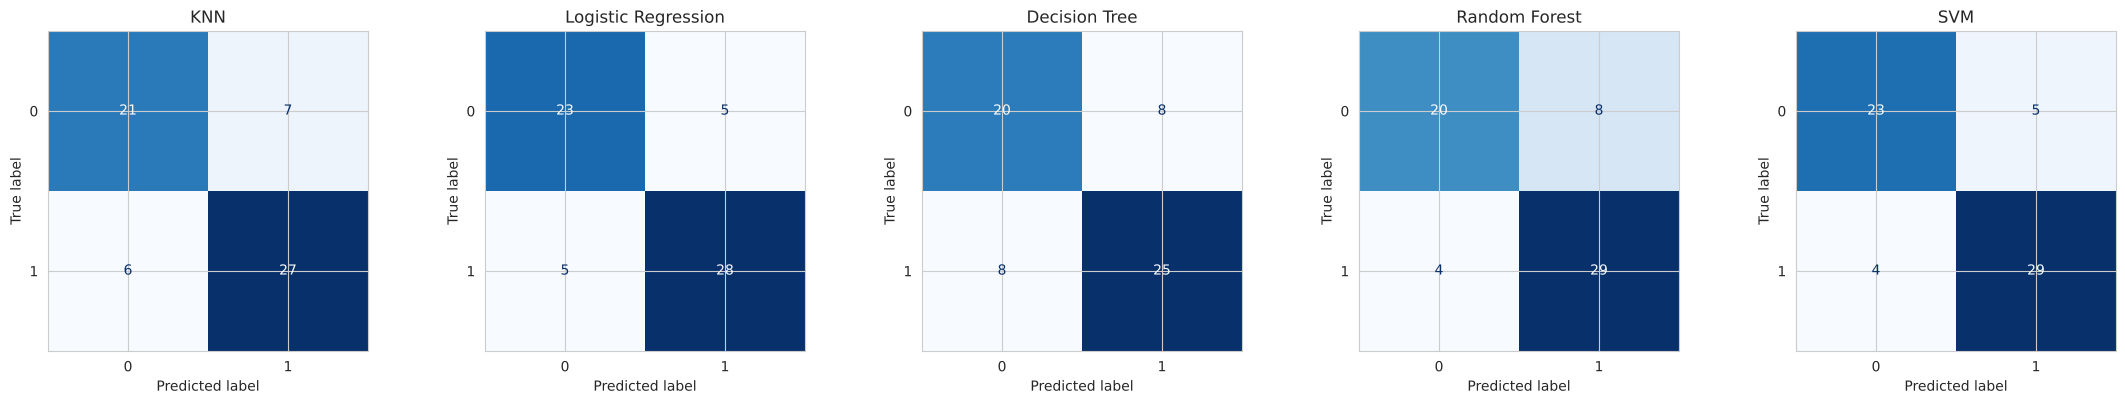

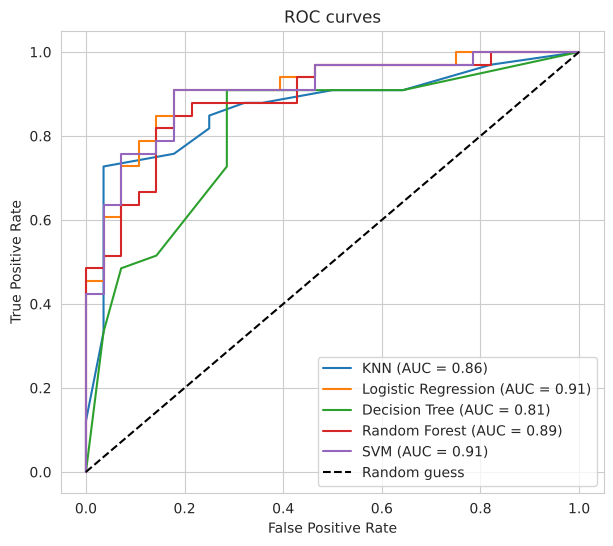

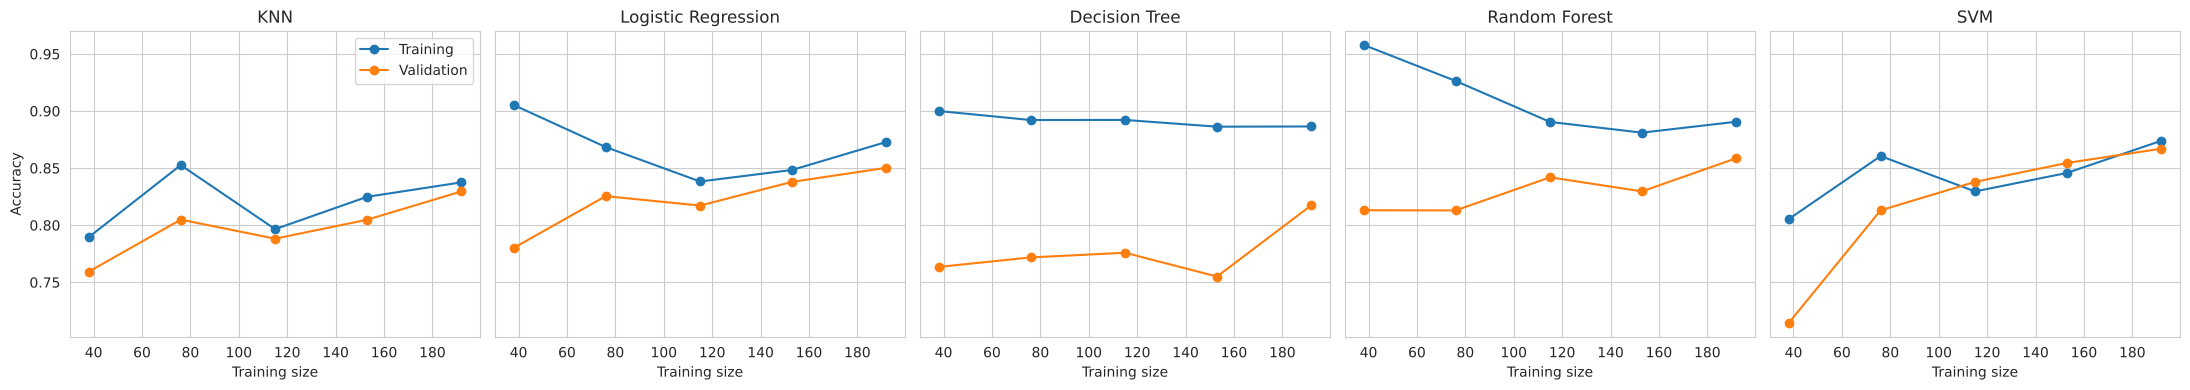

In [10]:
# Task 6: Model evaluation on the unseen test set
rows, preds = [], {}
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    preds[name] = (y_pred, y_prob)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, y_pred),
                 "Precision": precision_score(y_test, y_pred),
                 "Recall": recall_score(y_test, y_pred),
                 "F1-score": f1_score(y_test, y_pred),
                 "AUC": roc_auc_score(y_test, y_prob),
                 "CV F1 (train)": cv_scores[name]})
results = pd.DataFrame(rows).set_index("Model")
display(results.round(3))

# Confusion matrices
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, (y_pred, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

# ROC curves
plt.figure(figsize=(7, 6))
for name, (_, y_prob) in preds.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC curves")
plt.legend(); plt.show()

# Learning curves (bias-variance analysis)
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, (name, model) in zip(axes, best_models.items()):
    sizes, train_sc, val_sc = learning_curve(model, X_train, y_train, cv=cv,
                                             train_sizes=np.linspace(0.2, 1.0, 5), scoring="accuracy")
    ax.plot(sizes, train_sc.mean(axis=1), "o-", label="Training")
    ax.plot(sizes, val_sc.mean(axis=1), "o-", label="Validation")
    ax.set_title(name); ax.set_xlabel("Training size")
axes[0].set_ylabel("Accuracy"); axes[0].legend()
plt.tight_layout(); plt.show()

**Reading the learning curves (bias-variance):**
- *High bias (underfitting)*: training and validation curves are both low and close together. Adding data will not help.
- *High variance (overfitting)*: training accuracy is very high but validation accuracy is much lower, i.e. a big gap. Random Forest and Decision Tree (when deep) tend to show this gap; simple models such as Logistic Regression and a linear SVM have a small gap (low variance, slightly higher bias).
- A gap that shrinks as training size grows means more data would likely improve that model.

## Task 7: Comprehensive Model Comparison
- Create comparison table of all models' performance metrics
- Visualize performance comparison using bar charts
- Identify the best performing model based on multiple criteria
- Discuss trade-offs between different evaluation metrics

,Accuracy,Precision,Recall,F1-score,AUC,CV F1 (train),Overall score
Model,,,,,,,
SVM,0.852,0.853,0.879,0.866,0.906,0.882,0.884
Logistic Regression,0.836,0.848,0.848,0.848,0.911,0.874,0.878
Random Forest,0.803,0.784,0.879,0.829,0.889,0.878,0.865
KNN,0.787,0.794,0.818,0.806,0.865,0.853,0.841
Decision Tree,0.738,0.758,0.758,0.758,0.811,0.825,0.798


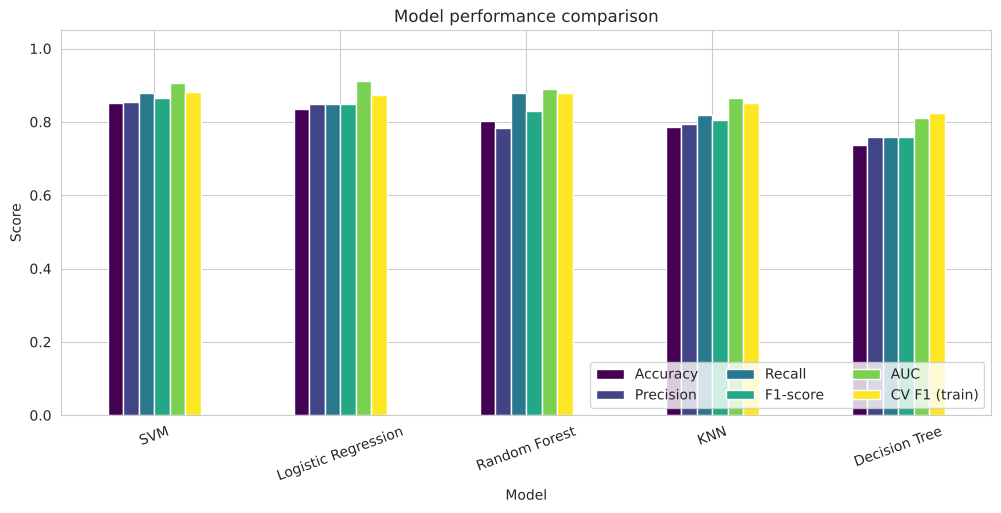

Best model: SVM
Accuracy         0.852
Precision        0.853
Recall           0.879
F1-score         0.866
AUC              0.906
CV F1 (train)    0.882
Overall score    0.884
Name: SVM, dtype: float64
Saved model/best_model.pkl and model/model_info.json


In [11]:
# Task 7: Comprehensive comparison
# We rank models on several criteria together: test F1, test AUC and cross-validated F1.
results["Overall score"] = results[["F1-score", "AUC", "CV F1 (train)"]].mean(axis=1)
comparison = results.sort_values("Overall score", ascending=False)
display(comparison.round(3))

# Bar charts
comparison.drop(columns="Overall score").plot(kind="bar", figsize=(12, 5), ylim=(0, 1.05), colormap="viridis")
plt.title("Model performance comparison"); plt.ylabel("Score"); plt.xticks(rotation=20)
plt.legend(loc="lower right", ncol=3); plt.show()

# Best model
best_name = comparison.index[0]
best_model = best_models[best_name]
print("Best model:", best_name)
print(comparison.loc[best_name].round(3))

# Save the best model (full pipeline: preprocessing + model) as a .pkl file
import os
os.makedirs("model", exist_ok=True)
with open("model/best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

# Also save the feature order and the model name, so the frontend uses exactly the same columns
info = {"model_name": best_name,
        "feature_order": list(X.columns),
        "test_metrics": comparison.loc[best_name].round(4).to_dict()}
with open("model/model_info.json", "w") as f:
    json.dump(info, f, indent=2)
print("Saved model/best_model.pkl and model/model_info.json")

### Trade-offs between evaluation metrics
- **Accuracy** is the share of all correct predictions. It is easy to understand but can hide problems when classes are imbalanced (here they are roughly balanced, so it is fair).
- **Precision** = of the patients predicted *sick*, how many really are. High precision means few false alarms.
- **Recall** = of the patients who are *really sick*, how many we find. In medicine, a missed patient (false negative) is more dangerous than a false alarm, so recall is very important.
- **F1-score** balances precision and recall in one number, so it is our main metric.
- **AUC** measures how well the model separates the two classes at every threshold; it does not depend on one cutoff.
- Raising recall usually lowers precision (and vice versa). We pick the model with the best *overall* balance (F1, AUC and cross-validated F1) and also check that its recall is high.